# Работа с текстовыми данными: вопросно-ответные системы (Information Retrieval-based Question Answering (IR-based)


Семинарист: [Федорова Валерия Сергеевна](https://www.hse.ru/org/persons/510438167)

### Что такое QA-система?

Question Answering (QA) — это направление обработки естественного языка (Natural Language Processing, NLP), связанное с разработкой систем, способных отвечать на вопросы пользователей на основе некоторого источника информации.

В отличие от обычного поиска, который возвращает документы или фрагменты текста, QA-система стремится предоставить пользователю непосредственно ответ на его вопрос.

Например:
- Пользователь: «Сколько рабочих дней отводится на подачу апелляции?»
- Система: «Апелляция подаётся в течение трёх рабочих дней с момента объявления результата».

Retrieval-based QA — подход к построению QA-систем, при котором ответ выбирается из заранее подготовленной базы знаний, а не генерируется моделью с нуля.

В рамках нашей работы мы реализуем именно такой подход.

## Подготовка базы вопросов и ответов

### База знаний

**База знаний (Knowledge Base)** — структурированное хранилище информации, которое используется системой для поиска и предоставления ответов.

В нашей реализации база знаний представлена парами:

$$(q_i, a_i)$$

где:
- $q_i$ — вопрос, сформулированный на основе нормативного документа;
- $a_i$ — соответствующий ему ответ.

При поступлении пользовательского запроса система сравнивает его с вопросами из базы знаний и выбирает наиболее подходящую пару.

Какой должна быть база знаний?
- База должна охватывать основные темы документа
- Ответы должны соответствовать первоисточнику
- Вопросы должны отражать возможные запросы пользователей
- Информация должна соответствовать действующей версии документа

### База знаний нашей работы

Возьмём 25 пар вопрос-ответ, составленных по основной части [ПОПАТКУСА](https://www.hse.ru/data/xf/055/297/0232/2.2.%20%D0%9F%D0%BE%D0%BB%D0%BE%D0%B6%D0%B5%D0%BD%D0%B8%D0%B5%20(%D1%81%20%D0%B8%D0%B7%D0%BC.%202026).pdf). Вопросы и ответы расположены в одинаковом порядке: questions[0] соответствует answers[0] и так далее.

In [ ]:
questions = [
    "Какие виды контроля и аттестации предусмотрены в НИУ ВШЭ?",
    "Как устроена десятибалльная система оценивания в НИУ ВШЭ?",
    "Какие оценки считаются положительными?",
    "Может ли преподаватель изменить объявленную оценку?",
    "Где можно ознакомиться с критериями и формулой выставления оценки?",
    "Какие обязанности есть у студента в рамках текущего контроля и промежуточной аттестации?",
    "Нужно ли указывать использование генеративных моделей при выполнении учебных работ?",
    "Могут ли поставить ноль за работу, если студент не указал использование генеративной модели?",
    "Можно ли использовать генеративный искусственный интеллект во время экзамена?",
    "Что получает студент, если не явился на экзамен?",
    "Какие причины отсутствия на экзамене считаются уважительными?",
    "В какой срок студент должен сообщить об уважительной причине отсутствия на экзамене?",
    "Может ли преподаватель освободить студента от экзамена?",
    "Где студент может узнать результаты промежуточной аттестации?",
    "Можно ли подать апелляцию, если студент не согласен с оценкой за экзамен?",
    "В какой срок можно подать апелляцию на результат экзамена?",
    "По каким причинам можно подать апелляцию?",
    "Кто рассматривает апелляцию студента?",
    "Что такое академическая задолженность?",
    "Можно ли пересдать экзамен, если студент уже получил положительную оценку?",
    "Сколько попыток даётся студенту для ликвидации академической задолженности?",
    "Кто принимает экзамен при первой и второй пересдаче?",
    "В течение какого срока студент должен ликвидировать академическую задолженность?",
    "Что происходит, если студент не ликвидировал задолженность после всех попыток?",
    "Можно ли перевестись на следующий курс при наличии академической задолженности?"
]

answers = [
    "В НИУ ВШЭ предусмотрены текущий контроль успеваемости, промежуточная аттестация и государственная итоговая аттестация.",
    "В НИУ ВШЭ используется десятибалльная шкала. Оценки 8–10 соответствуют отметке «отлично», 6–7 — «хорошо», 4–5 — «удовлетворительно», 0–3 — «неудовлетворительно».",
    "Положительными считаются оценки от 4 до 10 баллов.",
    "Преподаватель не вправе произвольно изменять объявленную оценку.",
    "Критерии оценивания, веса отдельных элементов и формула расчёта оценки указываются в программе учебной дисциплины и/или в электронной информационно-образовательной среде.",
    "Студент обязан выполнять предусмотренные программой дисциплины виды работ и соблюдать установленные сроки прохождения текущего контроля и промежуточной аттестации.",
    "Да. При использовании генеративной модели студент должен описать её применение: указать цели использования, название модели, источник или ссылку на неё и способ применения.",
    "Да. Неуказание факта использования генеративной модели в предусмотренных документом случаях может повлечь выставление нулевой оценки за работу.",
    "Использование генеративного искусственного интеллекта во время экзамена допускается только в том случае, если это предусмотрено программой дисциплины или отдельно разрешено преподавателем.",
    "При неявке на экзамен студенту по общему правилу выставляется ноль. Исключение возможно при наличии подтверждённой уважительной причины отсутствия.",
    "К уважительным причинам могут относиться болезнь, подтверждённая медицинскими документами, а также отдельные семейные или личные обстоятельства, признанные уважительными. Отсутствие по причине работы само по себе не считается уважительной причиной.",
    "Студент должен сообщить об уважительной причине в течение пяти учебных дней после пропущенного экзамена. Если болезнь продолжается дольше этого срока, срок отсчитывается после выздоровления. Обращение подаётся через ЭИОС с подтверждающими документами.",
    "Да, если такая возможность предусмотрена программой дисциплины и накопленные результаты студента позволяют освободить его от экзамена. При этом студент вправе отказаться от освобождения.",
    "Результаты промежуточной аттестации отражаются в электронной ведомости. Преподаватель направляет студентам расчёт баллов через ЭИОС в установленный срок.",
    "Апелляцию можно подать на результат экзамена или блокирующего элемента. При оценке 8 баллов и выше апелляция не допускается. Само по себе несогласие с оценкой не является основанием для апелляции.",
    "Апелляция подаётся в течение трёх рабочих дней с момента объявления результата.",
    "Основаниями могут быть несоответствие оценки установленным критериям, ошибки в формулировке задания, нарушение процедуры проведения экзамена или обстоятельства, помешавшие объективному оцениванию. Простого несогласия с оценкой недостаточно.",
    "Апелляцию рассматривает комиссия не менее чем из трёх преподавателей. Преподаватель, выставивший оспариваемую оценку, не может входить в состав комиссии.",
    "Академическая задолженность возникает при получении оценки ниже 4 баллов и/или невыполнении промежуточной аттестации, включая обязательную внешнюю оценку, без уважительной причины.",
    "По общему правилу пересдать дисциплину для повышения уже полученной положительной оценки нельзя. Исключения предусмотрены отдельными положениями документа.",
    "Для ликвидации академической задолженности студенту предоставляются две пересдачи после первоначальной аттестации: первая и вторая.",
    "Первую пересдачу, как правило, принимает преподаватель, проводивший первоначальную аттестацию. Вторую пересдачу принимает комиссия не менее чем из трёх преподавателей.",
    "Академическую задолженность необходимо ликвидировать в течение одного календарного года. В этот срок не включаются периоды болезни, академического отпуска и отпуска по беременности и родам.",
    "Если студент не ликвидировал хотя бы одну академическую задолженность после всех предусмотренных попыток в установленный срок, это является основанием для отчисления.",
    "Студент может быть переведён на следующий курс при наличии академической задолженности, если её количество не превышает установленного критического значения. В таком случае перевод осуществляется условно, а задолженность необходимо ликвидировать в начале следующего учебного года."
]

## Предобработка текстов

Выполним четыре операции:
1. Приведение к нижнему регистру
2. Токенизация — разделение текста на отдельные слова
3. Удаление стоп-слов — часто встречающихся слов, которые обычно не несут существенной смысловой нагрузки
4. Лемматизация — приведение слов к начальной форме

Для русского языка вопользуемся pymorphy3, а для токенизации — nltk

**Важный момент:** векторизуем именно вопросы, а не ответы. Это позволит искать совпадения по смыслу формулировок вопросов, а затем извлекать связанный с найденным вопросом ответ. Ответы мы не обрабатываем, поскольку будем искать наиболее похожий вопрос, а затем возвращать соответствующий ему исходный ответ.

In [ ]:
%pip install pymorphy3

In [ ]:
%pip install nltk

In [ ]:
import re
import nltk
import pymorphy3

from nltk.corpus import stopwords

nltk.download("stopwords")

morph = pymorphy3.MorphAnalyzer()

# Русские стоп-слова
stop_words = set(stopwords.words("russian"))

# Дополнительно добавим слова, которые часто встречаются в формулировках
# вопросов, но мало помогают различать их содержание
stop_words.update([
    "это", "такой", "также", "который", "свой",
    "можно", "ли", "какой", "какие", "какая",
    "какое", "сколько", 'ниу', 'вшэ'
])

def preprocess_text(text):
    # 1. Приведение к нижнему регистру
    text = text.lower()

    # 2. Токенизация
    tokens = re.findall(r"[а-яё]+", text)

    # 3. Лемматизация
    lemmas = [
        morph.parse(word)[0].normal_form
        for word in tokens
    ]

    # 4. Удаление стоп-слов после лемматизации
    lemmas = [
        word for word in lemmas
        if word not in stop_words and len(word) > 1
    ]

    return lemmas

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
processed_questions = [
    preprocess_text(question)
    for question in questions
]

# Посмотрим на результат предобработки
for original, processed in zip(questions[:5], processed_questions[:5]):
    print("Исходный вопрос:", original)
    print("После обработки:", processed)
    print("-" * 80)

Исходный вопрос: Какие виды контроля и аттестации предусмотрены в НИУ ВШЭ?
После обработки: ['вид', 'контроль', 'аттестация', 'предусмотреть']
--------------------------------------------------------------------------------
Исходный вопрос: Как устроена десятибалльная система оценивания в НИУ ВШЭ?
После обработки: ['устроить', 'десятибалльный', 'система', 'оценивание']
--------------------------------------------------------------------------------
Исходный вопрос: Какие оценки считаются положительными?
После обработки: ['оценка', 'считаться', 'положительный']
--------------------------------------------------------------------------------
Исходный вопрос: Может ли преподаватель изменить объявленную оценку?
После обработки: ['мочь', 'преподаватель', 'изменить', 'объявить', 'оценка']
--------------------------------------------------------------------------------
Исходный вопрос: Где можно ознакомиться с критериями и формулой выставления оценки?
После обработки: ['ознакомиться', 'критер

## Метод мешка слов

In [ ]:
import numpy as np

from sklearn.feature_extraction.text import CountVectorizer

# CountVectorizer будет получать уже токенизированные и лемматизированные слова
vectorizer = CountVectorizer(
    tokenizer=lambda x: x,
    preprocessor=lambda x: x,
    token_pattern=None,
    lowercase=False
)

# Создаём матрицу Bag of Words
X = vectorizer.fit_transform(processed_questions).toarray()

# Словарь
feature_names = vectorizer.get_feature_names_out()

print("Размер матрицы:", X.shape)
print("Размер словаря:", len(feature_names))

print("\nПример вектора первого вопроса:")
print(X[0])

print("\nСлова словаря:")
print(feature_names)

Размер матрицы: (25, 74)
Размер словаря: 74

Пример вектора первого вопроса:
[0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Слова словаря:
['академический' 'апелляция' 'аттестация' 'весь' 'вид' 'время' 'второй'
 'выполнение' 'выставление' 'генеративный' 'даваться' 'десятибалльный'
 'должный' 'задолженность' 'изменить' 'интеллект' 'искусственный'
 'использование' 'использовать' 'контроль' 'критерий' 'курс' 'ликвидация'
 'ликвидировать' 'модель' 'мочь' 'наличие' 'ноль' 'нужно' 'объявить'
 'обязанность' 'ознакомиться' 'освободить' 'отсутствие' 'оценивание'
 'оценка' 'первый' 'перевестись' 'пересдать' 'пересдача' 'подать'
 'положительный' 'получать' 'получить' 'попытка' 'поставить'
 'предусмотреть' 'преподаватель' 'принимать' 'причина' 'происходить'
 'промежуточный' 'работа' 'рамка' 'рассматривать' 'результат' 'система'
 'следующий' 'согласный' 'сообщить' 'срок' 'студент' 'считаться' 'т

## Подготовка тестовых вопросов

Для оценки качества системы подготовим тестовые вопросы, на которые есть ответ в нашей базе и на которые ответа нет.

In [ ]:
test_questions = [
    # Вопросы, на которые есть ответ в базе (10)

    "Какие баллы соответствуют неудовлетворительной оценке?",
    "Что должен указать студент, если при выполнении задания применял нейросеть?",
    "Сколько рабочих дней отводится на подачу апелляции?",
    "Кто должен принимать экзамен при второй пересдаче?",
    "При каких условиях студент может не сдавать экзамен?",
    "Как оценивается работа студента, если он пропустил экзамен без уважительной причины?",
    "Можно ли оспорить оценку 9 баллов за экзамен?",
    "Какой срок предоставляется для закрытия академического долга?",
    "Сколько всего попыток есть у студента, чтобы пересдать дисциплину после получения неудовлетворительной оценки?",
    "Что будет, если студент не закроет академический долг в течение установленного срока?",

    # Вопросы, на которые нет ответа в базе (5)

    "Как студент может оформить академический отпуск?",
    "Какие документы нужны для получения места в общежитии?",
    "Как рассчитывается размер государственной академической стипендии?",
    "Как студент может перевестись с платного обучения на бюджет?",
    "Какие требования предъявляются к оформлению выпускной квалификационной работы?"
]

correct_indices = [
    1, 6, 15, 21, 12, 9, 14, 22, 20, 23
]

# Для последних пяти вопросов правильного ответа в базе нет.

## Алгоритм поиска ответа по трем метрикам

### Для каждого тестового вопроса алгоритм будет:
1. Выполнять предобработку
2. Преобразовывать вопрос в вектор с помощью уже обученного vectorizer
3. Сравнивать его со всеми вопросами из базы
4. Выводить три наиболее похожих вопроса и соответствующие им ответы

### Метрики сходства текстов

После преобразования текстов в числовые векторы можно оценить, насколько два текста похожи друг на друга. Для этого используются специальные математические меры — метрики сходства (Similarity Metrics).

В нашей работе рассматриваются три метрики: коэффициент Жаккара, косинусное сходство и корреляция Пирсона.

1. **Коэффициент Жаккара (Jaccard Similarity)**

Коэффициент Жаккара измеряет сходство двух множеств на основе количества общих элементов относительно общего количества уникальных элементов. Для текстов такими элементами выступают уникальные слова.

$$J(A,B)=\frac{|A\cap B|}{|A\cup B|}$$

где:
- $A$ и $B$ — множества слов двух текстов;
- $(A\cap B)$ — пересечение множеств, то есть общие слова;
- $(A\cup B)$ — объединение множеств, то есть все уникальные слова обоих текстов.

Пример:

Рассмотрим два предложения:
- A: «студент может подать апелляцию»
- B: «студент подаёт апелляцию»

После предварительной обработки получим множества:
- A = [студент, мочь, подать, аппеляция]
- B = [студент, подать, аппеляция]

Общих элементов — 3, уникальных элементов в объединении — 4.

$$J(A,B)=\frac{3}{4}=0.75$$

Значение коэффициента находится в диапазоне от 0 до 1:
- 0 — множества не имеют общих элементов;
- 1 — множества полностью совпадают.

Особенность: коэффициент Жаккара учитывает только наличие общих слов, но не учитывает их частоту и порядок расположения.

2. **Косинусное сходство (Cosine Similarity)**

Косинусное сходство измеряет близость двух векторов на основе косинуса угла между ними.

В отличие от коэффициента Жаккара, эта метрика работает с числовыми векторами и позволяет учитывать частоту появления слов при использовании Bag of Words.

$$\operatorname{CosSim}(A,B)=
\frac{A\cdot B}{\|A\|\cdot\|B\|}$$

где:
- $A$ и $B$ — векторы текстов;
- $(A\cdot B)$ — скалярное произведение векторов;
- $(\|A\|) и (\|B\|)$ — их длины (евклидовы нормы).

Значение косинусного сходства для неотрицательных векторов Bag of Words находится в диапазоне от 0 до 1:
- 0 — векторы ортогональны, общие ненулевые признаки отсутствуют;
- 1 — векторы направлены одинаково.

Особенность: косинусное сходство учитывает не только наличие общих слов, но и их количество. При этом порядок слов в предложении не учитывается.

3. **Корреляция Пирсона (Pearson Correlation)**

Корреляция Пирсона измеряет силу и направление линейной связи между двумя наборами числовых значений.

В нашем случае сравниваются значения соответствующих координат векторов двух текстов.

$$r_{AB}=
\frac{\sum_{i=1}^{n}(A_i-\bar A)(B_i-\bar B)}
{\sqrt{\sum_{i=1}^{n}(A_i-\bar A)^2}
\sqrt{\sum_{i=1}^{n}(B_i-\bar B)^2}}$$

где:
- $A_i$ и $B_i$ — значения соответствующих координат векторов;
- $(\bar A)$ и $(\bar B)$ — средние значения координат;
- $n$ — размерность векторов.

Значение корреляции находится в диапазоне от −1 до 1:
- 1 — идеальная положительная линейная связь;
- 0 — отсутствие линейной корреляции;
- −1 — идеальная отрицательная линейная связь.

Особенность: корреляция Пирсона учитывает не абсолютные значения признаков, а то, насколько согласованно изменяются значения координат двух векторов. Поэтому она не является стандартной метрикой семантического сходства текстов, но может использоваться для экспериментального сравнения.

4. **Сравнение метрик**

| Характеристика | Жаккар | Косинусное сходство | Корреляция Пирсона |
|--------- | --------- | --------- |---------|
| **Тип данных** | Множества слов | Числовые векторы | Числовые векторы |
| **Учитывает частоту слов** | Нет | Да | Учитывает распределение значений |
| **Учитывает порядок слов** | Нет | Нет | Нет |
| **Диапазон значений** | [0; 1] | [−1; 1] (для BoW: [0; 1]) | [−1; 1] |
| **Основная идея** | Общие элементы | Угол между векторами | Линейная корреляция |


Вывод: все три метрики позволяют оценивать сходство текстовых представлений, но используют разные математические принципы. Поэтому интересно сравнить, какая из них лучше подходит для поиска релевантных вопросов в нашей базе знаний.

**Есть три важных момента:**

1. Жаккар и косинусное сходство — не одно и то же. Жаккар сравнивает множества уникальных слов, а косинусное сходство — числовые векторы. Поэтому два текста с одинаковым набором слов, но разной частотой слов могут получить разные оценки по этим метрикам.

2. Корреляция Пирсона не является прямой мерой семантической близости. Мы включили её в эксперимент, чтобы сравнить разные способы сопоставления векторов, но не следует автоматически считать её лучшей метрикой для текстового поиска.

3. Ни одна из этих метрик не понимает смысл текста сама по себе. Например, Bag of Words не распознаёт, что «подать апелляцию» и «оспорить результат экзамена» могут выражать близкий смысл. Именно эту проблему мы будем пытаться решить на следующем этапе с помощью эмбеддингов.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

def jaccard_similarity(tokens1, tokens2):
    set1 = set(tokens1)
    set2 = set(tokens2)

    union = set1 | set2

    if len(union) == 0:
        return 0.0

    intersection = set1 & set2

    return len(intersection) / len(union)


def cosine_similarities(query_vector, database_vectors):
    return cosine_similarity(
        query_vector.reshape(1, -1),
        database_vectors
    )[0]


def pearson_similarity(query_vector, database_vectors):
    scores = []

    for vector in database_vectors:
        # Если один из векторов константный,
        # корреляция не определена
        if np.std(query_vector) == 0 or np.std(vector) == 0:
            scores.append(0.0)
        else:
            correlation = np.corrcoef(query_vector, vector)[0, 1]

            if np.isnan(correlation):
                correlation = 0.0

            scores.append(correlation)

    return np.array(scores)

In [ ]:
def find_answers(query, top_n=3):
    # Предобработка нового вопроса
    processed_query = preprocess_text(query)

    # Векторизация с использованием словаря базы
    query_vector = vectorizer.transform([processed_query]).toarray()[0]

    # Сходство по трём метрикам
    jaccard_scores = np.array([
        jaccard_similarity(processed_query, question)
        for question in processed_questions
    ])

    cosine_scores = cosine_similarities(query_vector, X)

    pearson_scores = pearson_similarity(query_vector, X)

    scores_by_metric = {
        "Жаккар": jaccard_scores,
        "Косинусное сходство": cosine_scores,
        "Корреляция Пирсона": pearson_scores
    }

    results = {}

    for metric_name, scores in scores_by_metric.items():

        # Индексы top_n наиболее похожих вопросов
        top_indices = np.argsort(scores)[::-1][:top_n]

        results[metric_name] = []

        for idx in top_indices:
            results[metric_name].append({
                "index": idx,
                "score": scores[idx],
                "matched_question": questions[idx],
                "answer": answers[idx]
            })

    return results

## Результаты

In [ ]:
import pandas as pd

evaluation_table = []

for i, query in enumerate(test_questions):

    # Получаем правильный ответ из базы, если он существует
    if i < len(correct_indices):
        correct_answer = answers[correct_indices[i]]
    else:
        correct_answer = "Ответ отсутствует в базе"

    # Получаем результаты для всех трех метрик
    results = find_answers(query, top_n=1)

    jaccard_result = results["Жаккар"][0]
    cosine_result = results["Косинусное сходство"][0]
    pearson_result = results["Корреляция Пирсона"][0]

    evaluation_table.append({
        "Вопрос": query,
        "Правильный ответ": correct_answer,

        "Ответ системы (Жаккар)": jaccard_result["answer"],
        "Метрика Жаккара": round(jaccard_result["score"], 4),

        "Ответ системы (косинус)": cosine_result["answer"],
        "Косинусная близость": round(cosine_result["score"], 4),

        "Ответ системы (корреляция)": pearson_result["answer"],
        "Корреляция Пирсона": round(pearson_result["score"], 4)
    })

evaluation_df = pd.DataFrame(evaluation_table)

# Отображаем таблицу
evaluation_df

,Вопрос,Правильный ответ,Ответ системы (Жаккар),Метрика Жаккара,Ответ системы (косинус),Косинусная близость,Ответ системы (корреляция),Корреляция Пирсона
0,Какие баллы соответствуют неудовлетворительной...,В НИУ ВШЭ используется десятибалльная шкала. О...,Положительными считаются оценки от 4 до 10 бал...,0.1667,Положительными считаются оценки от 4 до 10 бал...,0.5774,Положительными считаются оценки от 4 до 10 бал...,0.5694
1,"Что должен указать студент, если при выполнени...",Да. При использовании генеративной модели студ...,Академическую задолженность необходимо ликвиди...,0.1667,Академическую задолженность необходимо ликвиди...,0.3780,Академическую задолженность необходимо ликвиди...,0.3311
2,Сколько рабочих дней отводится на подачу апелл...,Апелляция подаётся в течение трёх рабочих дней...,Апелляцию рассматривает комиссия не менее чем ...,0.1429,Апелляцию рассматривает комиссия не менее чем ...,0.5774,Апелляцию рассматривает комиссия не менее чем ...,0.5694
3,Кто должен принимать экзамен при второй пересд...,"Первую пересдачу, как правило, принимает препо...","Первую пересдачу, как правило, принимает препо...",0.6667,"Первую пересдачу, как правило, принимает препо...",0.8000,"Первую пересдачу, как правило, принимает препо...",0.7855
4,При каких условиях студент может не сдавать эк...,"Да, если такая возможность предусмотрена прогр...","Да, если такая возможность предусмотрена прогр...",0.4286,"Да, если такая возможность предусмотрена прогр...",0.7746,"Да, если такая возможность предусмотрена прогр...",0.7636
5,"Как оценивается работа студента, если он пропу...",При неявке на экзамен студенту по общему прави...,Студент должен сообщить об уважительной причин...,0.3636,Студент должен сообщить об уважительной причин...,0.6325,Студент должен сообщить об уважительной причин...,0.5998
6,Можно ли оспорить оценку 9 баллов за экзамен?,Апелляцию можно подать на результат экзамена и...,По общему правилу пересдать дисциплину для пов...,0.2500,По общему правилу пересдать дисциплину для пов...,0.5774,По общему правилу пересдать дисциплину для пов...,0.5611
7,Какой срок предоставляется для закрытия академ...,Академическую задолженность необходимо ликвиди...,Академическую задолженность необходимо ликвиди...,0.2000,Академическую задолженность необходимо ликвиди...,0.5345,Академическую задолженность необходимо ликвиди...,0.5156
8,"Сколько всего попыток есть у студента, чтобы п...",Для ликвидации академической задолженности сту...,Если студент не ликвидировал хотя бы одну акад...,0.2727,Если студент не ликвидировал хотя бы одну акад...,0.5477,Если студент не ликвидировал хотя бы одну акад...,0.5118
9,"Что будет, если студент не закроет академическ...",Если студент не ликвидировал хотя бы одну акад...,Академическую задолженность необходимо ликвиди...,0.4000,Академическую задолженность необходимо ликвиди...,0.7559,Академическую задолженность необходимо ликвиди...,0.7396


### Top-N и Threshold

**Top-N** — количество наиболее релевантных результатов, которые система возвращает после ранжирования.

Например, Top-3 означает, что система выбирает три вопроса из базы знаний с наибольшими значениями сходства.

**Threshold (порог сходства)** — минимальное значение оценки релевантности, при котором система считает найденный результат достаточно подходящим для выдачи ответа.

Логика работы:
- Если оценка лучшего кандидата не ниже порога, система возвращает соответствующий ответ.
- Если оценка ниже порога, система отказывается от ответа.
Порог позволяет снизить вероятность выдачи нерелевантной информации, однако его слишком высокое значение может приводить к отказам даже в ситуациях, когда подходящий ответ присутствует в базе.

### Метрики оценки QA-систем

Для оценки качества поиска необходимо учитывать не только способность находить правильный ответ, но и способность системы распознавать ситуации, когда ответа в базе нет.

В нашей работе используются следующие показатели:

1. Top-1 Accuracy

Доля вопросов, для которых правильный ответ оказался на первом месте и был выдан системой.

2. Top-3 Accuracy

Доля вопросов, для которых правильный ответ оказался среди трёх наиболее релевантных кандидатов.

3. Rejection Accuracy

Доля вопросов, на которые система правильно отказалась отвечать, поскольку подходящей информации нет в базе.

4. Общая точность Top-1

Доля всех тестовых запросов, обработанных корректно: система либо выдала правильный ответ, либо правильно отказалась от ответа.

**Важно:** это метрики именно нашей системы, а не универсальный набор метрик для всех QA-систем. Набор метрик может существенно отличаться в зависимости от используемых моделей или бизнес-задач.

In [ ]:
thresholds = {
    "Жаккар": 0.15,
    "Косинусное сходство": 0.45,
    "Корреляция Пирсона": 0.40
}

In [ ]:
def predict_answer(query, metric_name, threshold, top_n=3):

    results = find_answers(query, top_n=top_n)
    matches = results[metric_name]

    best_match = matches[0]

    if best_match["score"] < threshold:
        return {
            "status": "Ответ не найден",
            "score": best_match["score"],
            "question": None,
            "answer": None
        }

    return {
        "status": "Ответ найден",
        "score": best_match["score"],
        "question": best_match["matched_question"],
        "answer": best_match["answer"]
    }

In [ ]:
import pandas as pd

evaluation_results = []

total_questions = len(test_questions)
n_answerable = len(correct_indices)
n_unanswerable = total_questions - n_answerable

for metric_name, threshold in thresholds.items():

    correct_top1 = 0
    correct_top3 = 0
    correct_rejections = 0

    for i, query in enumerate(test_questions):

        # Получаем предсказание с учётом порога
        prediction = predict_answer(
            query,
            metric_name,
            threshold
        )

        # Получаем три наиболее похожих вопроса
        results = find_answers(query, top_n=3)[metric_name]

        if i < n_answerable:

            # Правильно найденный ответ на первом месте
            if (
                prediction["status"] == "Ответ найден"
                and results[0]["index"] == correct_indices[i]
            ):
                correct_top1 += 1

            # Правильный ответ присутствует в топ-3
            if any(
                match["index"] == correct_indices[i]
                for match in results
            ):
                correct_top3 += 1

        else:

            # Система правильно отказалась отвечать
            if prediction["status"] == "Ответ не найден":
                correct_rejections += 1

    # Рассчитываем итоговые показатели
    top1_accuracy = (
        correct_top1 / n_answerable
        if n_answerable > 0 else 0
    )

    top3_accuracy = (
        correct_top3 / n_answerable
        if n_answerable > 0 else 0
    )

    rejection_accuracy = (
        correct_rejections / n_unanswerable
        if n_unanswerable > 0 else 0
    )

    total_accuracy = (
        correct_top1 + correct_rejections
    ) / total_questions if total_questions > 0 else 0

    evaluation_results.append({
        "Метрика": metric_name,

        f"Правильно найдено в Top-1 (из {n_answerable})":
            f"{correct_top1}/{n_answerable}",

        f"Правильно найдено в Top-3 (из {n_answerable})":
            f"{correct_top3}/{n_answerable}",

        f"Правильные отказы (из {n_unanswerable})":
            f"{correct_rejections}/{n_unanswerable}",

        "Общая точность Top-1": total_accuracy,
        "Точность Top-3": top3_accuracy,
        "Точность отказа": rejection_accuracy
    })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df

,Метрика,Правильно найдено в Top-1 (из 10),Правильно найдено в Top-3 (из 10),Правильные отказы (из 5),Общая точность Top-1,Точность Top-3,Точность отказа
0,Жаккар,3/10,7/10,2/5,0.333333,0.7,0.4
1,Косинусное сходство,3/10,7/10,2/5,0.333333,0.7,0.4
2,Корреляция Пирсона,3/10,6/10,2/5,0.333333,0.6,0.4


## Попробуем что-то посложнее мешка слов: эмбеддинги

1. **Что такое эмбеддинг?**

Эмбеддинг (embedding) — это числовое представление объекта, например слова, предложения или целого документа. С помощью эмбеддингов текст переводится в формат, с которым могут работать алгоритмы машинного обучения.

Например, вместо того чтобы хранить предложение в виде последовательности слов:
«Как студент может подать апелляцию?»

мы можем представить его в виде вектора чисел:

$$
\mathbf{v} = [0.12, -0.34, 0.56, \ldots, 0.08]
$$

Главная идея: модель обучается так, чтобы тексты со схожим смыслом получали близкие векторные представления. Поэтому предложения «Как студент может подать апелляцию?» и «В какие сроки можно оспорить оценку?» могут оказаться ближе друг к другу в векторном пространстве, чем предложения, не связанные по смыслу.

Эмбеддинги позволяют сравнивать тексты не только по совпадению отдельных слов, но и по их смысловой близости.

2. **Как можно получить эмбеддинги текста?**

Существует несколько подходов к векторному представлению текста. Рассмотрим два основных метода:
- Word2Vec

Word2Vec — один из классических методов получения эмбеддингов, в котором каждому слову ставится в соответствие вектор фиксированной размерности.

Модель обучается на большом корпусе текстов и использует контекст слова, то есть слова, которые встречаются рядом с ним. Основная идея заключается в том, что слова, употребляющиеся в похожих контекстах, получают близкие векторные представления.

Существуют две основные архитектуры Word2Vec:
- CBOW (Continuous Bag of Words) — предсказывает целевое слово по окружающим его словам.
- Skip-gram — предсказывает окружающие слова по заданному целевому слову.

Важная особенность: Word2Vec формирует один фиксированный вектор для каждого слова. Например, слово «ключ» будет иметь одно и то же представление независимо от того, используется ли оно в значении предмета для открывания замка или в значении источника воды.

Кроме того, Word2Vec изначально работает на уровне отдельных слов. Чтобы получить представление целого предложения, необходимо дополнительно объединить векторы его слов, например усреднить их.

- Трансформеры

Трансформеры (Transformers) — архитектура нейронных сетей, которая позволяет учитывать контекст, в котором используется каждое слово.

В отличие от Word2Vec, трансформер анализирует не только отдельные слова и их окружение в процессе обучения, но и взаимосвязи между словами внутри конкретного входного текста.

Ключевой механизм архитектуры — Self-Attention (механизм самовнимания). Он позволяет модели определять, какие другие слова предложения важны для интерпретации каждого конкретного слова.

Например, рассмотрим два предложения:
- «Студент получил ключ от аудитории».
- «Студент нашёл ключ к решению задачи».

Слово «ключ» имеет разный смысл в зависимости от контекста. Контекстная модель может сформировать для него разные векторные представления в каждом из предложений.

Главное отличие: трансформер позволяет получать контекстные представления слов, а специальные модели на его основе — векторные представления целых предложений.

3. **Word2Vec и трансформеры: в чём разница?**

| Критерий | Word2Vec | Трансформеры |
|--------- | --------- | --------- |
| **Единица представления** | Отдельное слово | Слова и целые предложения |
| **Учёт контекста** | Учитывает локальное окружение при обучении | Учитывает контекст конкретного входного текста |
| **Многозначность слов** | Один вектор на слово | Представление зависит от контекста |
| **Представление предложения** | Нужно дополнительно агрегировать векторы слов | Можно получить специальный эмбеддинг предложения |
| **Смысловая близость** | Через сходство векторов слов | Через контекстные представления текста |

Таким образом, Word2Vec хорошо подходит для получения векторов отдельных слов, но при поиске похожих предложений может терять информацию о контексте и взаимосвязях между словами. Трансформеры позволяют учитывать эти особенности и лучше подходят для задач семантического поиска.

4. **Какую модель возьмем мы?**
В нашем эксперименте используется модель [paraphrase-multilingual-MiniLM-L12-v2](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2).

Это компактная мультиязычная модель на основе архитектуры трансформера, предназначенная для получения эмбеддингов предложений. Она обучена так, чтобы предложения с близким смыслом имели похожие векторные представления.

Основные характеристики:
- Поддерживает несколько языков, включая русский.
- Учитывает контекст слов внутри предложения.
- Формирует эмбеддинг размерностью 384.
- Позволяет сравнивать предложения по косинусному сходству.

В нашем случае модель преобразует каждый вопрос из базы знаний в вектор. Когда пользователь вводит новый вопрос, модель аналогичным образом получает его эмбеддинг, после чего мы сравниваем его с векторами вопросов из базы знаний.

5. **Как эмбеддинги используются в нашей QA-системе?**

Процесс поиска ответа состоит из нескольких этапов:
1. Подготовка базы знаний. Каждый вопрос из базы преобразуется в эмбеддинг.
2. Обработка запроса. Новый вопрос пользователя преобразуется в вектор с помощью той же модели.
3. Поиск похожих вопросов. Рассчитывается косинусное сходство между вектором запроса и эмбеддингами вопросов из базы.
4. Ранжирование. Вопросы сортируются по степени сходства, и система выбирает наиболее подходящие варианты.
5. Возврат ответа. Если сходство с наиболее подходящим вопросом превышает установленный порог, система возвращает связанный с ним ответ. В противном случае отказывается от ответа.

Таким образом, мы переходим от поиска совпадающих слов к семантическому поиску, при котором система пытается найти вопрос с похожим смыслом, даже если пользователь сформулировал его другими словами.

### Загружаем модель

In [ ]:
!pip install -q sentence-transformers

В результате каждый вопрос будет представлен вектором из 384 чисел, которые мы не можем проинтерпретировать. То есть вместо матрицы «вопросы × слова» (как было в методе мешка слов) у нас теперь матрица «вопросы × 384 признака».

In [ ]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Загружаем мультиязычную модель
model = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

# Получаем эмбеддинги вопросов из базы
question_embeddings = model.encode(
    questions,
    convert_to_numpy=True,
    show_progress_bar=True
)

print("Размер матрицы эмбеддингов:", question_embeddings.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Размер матрицы эмбеддингов: (25, 384)


### Алгоритм поиска ответов по двум метрикам

Оставим две метрики, которые работают непосредственно с эмбеддингами:
1. Косинусное сходство — измеряет близость векторов по углу между ними.
2. Корреляция Пирсона — оценивает силу линейной связи между значениями двух векторов.

**Важно:** так как теперь у нас нет набора слов, то мы не можем вычислить метрику Жаккара, поэтому не будем ее использовать.

In [ ]:
def find_answers(query, top_n=3):

    # Получаем эмбеддинг запроса
    query_embedding = model.encode(
        [query],
        convert_to_numpy=True
    )[0]

    # Косинусное сходство
    cosine_scores = cosine_similarity(
        query_embedding.reshape(1, -1),
        question_embeddings
    )[0]

    # Корреляция Пирсона
    pearson_scores = pearson_similarity(
        query_embedding,
        question_embeddings
    )

    scores_by_metric = {
        "Косинусное сходство": cosine_scores,
        "Корреляция Пирсона": pearson_scores
    }

    results = {}

    for metric_name, scores in scores_by_metric.items():

        top_indices = np.argsort(scores)[::-1][:top_n]

        results[metric_name] = []

        for idx in top_indices:
            results[metric_name].append({
                "index": idx,
                "score": scores[idx],
                "matched_question": questions[idx],
                "answer": answers[idx]
            })

    return results

### Результаты

In [ ]:
evaluation_table = []

for i, query in enumerate(test_questions):

    if i < len(correct_indices):
        correct_answer = answers[correct_indices[i]]
    else:
        correct_answer = "Ответ отсутствует в базе"

    results = find_answers(query, top_n=1)

    cosine_result = results["Косинусное сходство"][0]
    pearson_result = results["Корреляция Пирсона"][0]

    evaluation_table.append({
        "Вопрос": query,
        "Правильный ответ": correct_answer,

        "Ответ системы (косинус)": cosine_result["answer"],
        "Косинусная близость": round(cosine_result["score"], 4),

        "Ответ системы (корреляция)": pearson_result["answer"],
        "Корреляция Пирсона": round(pearson_result["score"], 4)
    })

evaluation_df = pd.DataFrame(evaluation_table)

evaluation_df

,Вопрос,Правильный ответ,Ответ системы (косинус),Косинусная близость,Ответ системы (корреляция),Корреляция Пирсона
0,Какие баллы соответствуют неудовлетворительной...,В НИУ ВШЭ используется десятибалльная шкала. О...,Положительными считаются оценки от 4 до 10 бал...,0.8026,Положительными считаются оценки от 4 до 10 бал...,0.8026
1,"Что должен указать студент, если при выполнени...",Да. При использовании генеративной модели студ...,Студент обязан выполнять предусмотренные прогр...,0.7441,Студент обязан выполнять предусмотренные прогр...,0.7441
2,Сколько рабочих дней отводится на подачу апелл...,Апелляция подаётся в течение трёх рабочих дней...,Апелляция подаётся в течение трёх рабочих дней...,0.7436,Апелляция подаётся в течение трёх рабочих дней...,0.7436
3,Кто должен принимать экзамен при второй пересд...,"Первую пересдачу, как правило, принимает препо...","Первую пересдачу, как правило, принимает препо...",0.9083,"Первую пересдачу, как правило, принимает препо...",0.9083
4,При каких условиях студент может не сдавать эк...,"Да, если такая возможность предусмотрена прогр...",К уважительным причинам могут относиться болез...,0.8240,К уважительным причинам могут относиться болез...,0.8240
5,"Как оценивается работа студента, если он пропу...",При неявке на экзамен студенту по общему прави...,Студент должен сообщить об уважительной причин...,0.8444,Студент должен сообщить об уважительной причин...,0.8444
6,Можно ли оспорить оценку 9 баллов за экзамен?,Апелляцию можно подать на результат экзамена и...,По общему правилу пересдать дисциплину для пов...,0.7020,По общему правилу пересдать дисциплину для пов...,0.7020
7,Какой срок предоставляется для закрытия академ...,Академическую задолженность необходимо ликвиди...,Академическую задолженность необходимо ликвиди...,0.8805,Академическую задолженность необходимо ликвиди...,0.8805
8,"Сколько всего попыток есть у студента, чтобы п...",Для ликвидации академической задолженности сту...,Для ликвидации академической задолженности сту...,0.6775,Для ликвидации академической задолженности сту...,0.6775
9,"Что будет, если студент не закроет академическ...",Если студент не ликвидировал хотя бы одну акад...,Академическую задолженность необходимо ликвиди...,0.9114,Академическую задолженность необходимо ликвиди...,0.9114


In [ ]:
thresholds = {
    "Косинусное сходство": 0.67,
    "Корреляция Пирсона": 0.67
}

In [ ]:
def predict_answer(query, metric_name, threshold, top_n=3):

    results = find_answers(query, top_n=top_n)
    matches = results[metric_name]

    best_match = matches[0]

    if best_match["score"] < threshold:
        return {
            "status": "Ответ не найден",
            "score": best_match["score"],
            "question": None,
            "answer": None
        }

    return {
        "status": "Ответ найден",
        "score": best_match["score"],
        "question": best_match["matched_question"],
        "answer": best_match["answer"]
    }

In [ ]:
import pandas as pd

evaluation_results = []

total_questions = len(test_questions)
n_answerable = len(correct_indices)
n_unanswerable = total_questions - n_answerable

for metric_name, threshold in thresholds.items():

    correct_top1 = 0
    correct_top3 = 0
    correct_rejections = 0

    for i, query in enumerate(test_questions):

        # Получаем предсказание с учётом порога
        prediction = predict_answer(
            query,
            metric_name,
            threshold
        )

        # Получаем три наиболее похожих вопроса
        results = find_answers(query, top_n=3)[metric_name]

        if i < n_answerable:

            # Правильно найденный ответ на первом месте
            if (
                prediction["status"] == "Ответ найден"
                and results[0]["index"] == correct_indices[i]
            ):
                correct_top1 += 1

            # Правильный ответ присутствует в топ-3
            if any(
                match["index"] == correct_indices[i]
                for match in results
            ):
                correct_top3 += 1

        else:

            # Система правильно отказалась отвечать
            if prediction["status"] == "Ответ не найден":
                correct_rejections += 1

    # Рассчитываем итоговые показатели
    top1_accuracy = (
        correct_top1 / n_answerable
        if n_answerable > 0 else 0
    )

    top3_accuracy = (
        correct_top3 / n_answerable
        if n_answerable > 0 else 0
    )

    rejection_accuracy = (
        correct_rejections / n_unanswerable
        if n_unanswerable > 0 else 0
    )

    total_accuracy = (
        correct_top1 + correct_rejections
    ) / total_questions if total_questions > 0 else 0

    evaluation_results.append({
        "Метрика": metric_name,

        f"Правильно найдено в Top-1 (из {n_answerable})":
            f"{correct_top1}/{n_answerable}",

        f"Правильно найдено в Top-3 (из {n_answerable})":
            f"{correct_top3}/{n_answerable}",

        f"Правильные отказы (из {n_unanswerable})":
            f"{correct_rejections}/{n_unanswerable}",

        "Общая точность Top-1": total_accuracy,
        "Точность Top-3": top3_accuracy,
        "Точность отказа": rejection_accuracy
    })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df

,Метрика,Правильно найдено в Top-1 (из 10),Правильно найдено в Top-3 (из 10),Правильные отказы (из 5),Общая точность Top-1,Точность Top-3,Точность отказа
0,Косинусное сходство,4/10,7/10,4/5,0.533333,0.7,0.8
1,Корреляция Пирсона,4/10,7/10,4/5,0.533333,0.7,0.8


## Попробуем улучшить нашу систему на основе эмбеддингов

### Reranking

Reranking (переранжирование) — дополнительный этап обработки поисковой выдачи, на котором ранее найденные кандидаты повторно оцениваются и сортируются с использованием дополнительной информации или более сложного критерия.

В нашей реализации используется двухэтапный подход:

**Этап 1. Первичный поиск.** С помощью эмбеддингов выбираются пять наиболее похожих вопросов из базы знаний.

**Этап 2. Переранжирование.** Для каждого найденного кандидата дополнительно рассчитывается сходство пользовательского запроса с соответствующим ответом.

Итоговая оценка представляет собой взвешенную сумму двух показателей:

$$
Score = \alpha S_q + (1-\alpha)S_a
$$

где:
- $S_q$ — сходство пользовательского запроса с вопросом из базы;
- $S_a$ — сходство пользовательского запроса с ответом из базы;
- $\alpha\$ — вес первого показателя.

После этого кандидаты сортируются по итоговой оценке, и система выбирает наиболее подходящий ответ.

## **Очень важно**: итоговая оценка, которую мы используем не является общепринятой. Это только одно из возможных усреднений по двум показателям. Как и по каким метрикам в итоге будет отбираться ответ, зависит от вашей задачи.

### Получим эмбеддинги ответов

In [ ]:
answer_embeddings = model.encode(
    answers,
    convert_to_numpy=True,
    show_progress_bar=True
)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

### Напишем алгоритм системы

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def find_answers_reranked(query, top_n=5, alpha=0.5):

    # Эмбеддинг пользовательского вопроса
    query_embedding = model.encode(
        [query],
        convert_to_numpy=True
    )

    # Сходство с вопросами базы
    question_scores = cosine_similarity(
        query_embedding,
        question_embeddings
    )[0]

    # Сходство с ответами базы
    answer_scores = cosine_similarity(
        query_embedding,
        answer_embeddings
    )[0]

    # Первичный отбор Top-5 по сходству вопросов
    candidate_indices = np.argsort(
        question_scores
    )[::-1][:top_n]

    results = []

    for idx in candidate_indices:

        # Итоговая оценка
        final_score = (
            alpha * question_scores[idx]
            + (1 - alpha) * answer_scores[idx]
        )

        results.append({
            "index": idx,
            "question_score": question_scores[idx],
            "answer_score": answer_scores[idx],
            "final_score": final_score,
            "matched_question": questions[idx],
            "answer": answers[idx]
        })

    # Сортируем кандидатов по итоговой оценке
    results = sorted(
        results,
        key=lambda x: x["final_score"],
        reverse=True
    )

    return results

### Рассмотрим результат на конкретном примере

In [ ]:
query = "Сколько времени даётся на пересдачу экзамена?"

results = find_answers_reranked(query)

for i, result in enumerate(results, 1):

    print(f"\nКандидат {i}")
    print("Вопрос:", result["matched_question"])
    print("Ответ:", result["answer"])
    print(f"Сходство вопросов: {result['question_score']:.3f}")
    print(f"Сходство с ответом: {result['answer_score']:.3f}")
    print(f"Итоговая оценка: {result['final_score']:.3f}")


Кандидат 1
Вопрос: В какой срок студент должен сообщить об уважительной причине отсутствия на экзамене?
Ответ: Студент должен сообщить об уважительной причине в течение пяти учебных дней после пропущенного экзамена. Если болезнь продолжается дольше этого срока, срок отсчитывается после выздоровления. Обращение подаётся через ЭИОС с подтверждающими документами.
Сходство вопросов: 0.719
Сходство с ответом: 0.700
Итоговая оценка: 0.709

Кандидат 2
Вопрос: В какой срок можно подать апелляцию на результат экзамена?
Ответ: Апелляция подаётся в течение трёх рабочих дней с момента объявления результата.
Сходство вопросов: 0.758
Сходство с ответом: 0.534
Итоговая оценка: 0.646

Кандидат 3
Вопрос: Где студент может узнать результаты промежуточной аттестации?
Ответ: Результаты промежуточной аттестации отражаются в электронной ведомости. Преподаватель направляет студентам расчёт баллов через ЭИОС в установленный срок.
Сходство вопросов: 0.544
Сходство с ответом: 0.522
Итоговая оценка: 0.533

Канд

### Метрики качества

In [ ]:
import pandas as pd

# Параметры модели
alpha = 0.7
threshold = 0.6448

evaluation_results = []

total_questions = len(test_questions)
n_answerable = len(correct_indices)
n_unanswerable = total_questions - n_answerable

correct_top1 = 0
correct_top3 = 0
correct_rejections = 0

for i, query in enumerate(test_questions):

    # Получаем результаты поиска с переранжированием
    results = find_answers_reranked(
        query,
        top_n=5,
        alpha=alpha
    )

    best_match = results[0]

    # Проверяем, найден ли ответ
    answer_found = best_match["final_score"] >= threshold

    if i < n_answerable:

        # Правильный ответ на первом месте с учетом порога
        if (
            answer_found
            and best_match["index"] == correct_indices[i]
        ):
            correct_top1 += 1

        # Правильный ответ входит в Top-3
        if any(
            result["index"] == correct_indices[i]
            for result in results[:3]
        ):
            correct_top3 += 1

    else:

        # Правильный отказ от ответа
        if not answer_found:
            correct_rejections += 1


# Рассчитываем метрики
top1_accuracy = correct_top1 / n_answerable
top3_accuracy = correct_top3 / n_answerable
rejection_accuracy = correct_rejections / n_unanswerable

total_accuracy = (
    correct_top1 + correct_rejections
) / total_questions


# Формируем таблицу
evaluation_results.append({
    "Метрика": "Эмбеддинги + реранкинг",
    f"Правильно найдено в Top-1 (из {n_answerable})":
        f"{correct_top1}/{n_answerable}",
    f"Правильно найдено в Top-3 (из {n_answerable})":
        f"{correct_top3}/{n_answerable}",
    f"Правильные отказы (из {n_unanswerable})":
        f"{correct_rejections}/{n_unanswerable}",
    "Общая точность Top-1": total_accuracy,
    "Точность Top-3": top3_accuracy,
    "Точность отказа": rejection_accuracy
})

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df

,Метрика,Правильно найдено в Top-1 (из 10),Правильно найдено в Top-3 (из 10),Правильные отказы (из 5),Общая точность Top-1,Точность Top-3,Точность отказа
0,Эмбеддинги + реранкинг,7/10,8/10,4/5,0.733333,0.8,0.8


## Создадим интерактивную ячейку для нашего чат-бота

In [ ]:
!pip install -q ipywidgets

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

# Заголовок и поле ввода
question_label = widgets.HTML(
    value="<b style='font-size: 15px;'>Вопрос</b>"
)

question_input = widgets.Textarea(
    value='',
    placeholder='Введите свой вопрос...',
    layout=widgets.Layout(
        width='50%',
        height='90px',
        box_sizing='border-box'
    )
)

# Кнопка поиска
search_button = widgets.Button(
    description='Отправить',
    button_style='primary',
    icon='paper-plane',
    layout=widgets.Layout(
        width='180px',
        height='40px'
    )
)

# Область вывода
output = widgets.Output(
    layout=widgets.Layout(width='50%')
)

# Параметры поиска
ALPHA = 0.7
THRESHOLD = 0.6448  # Замените на выбранный порог модели


def search_answer(button):
    with output:
        clear_output()

        query = question_input.value.strip()

        if not query:
            display(Markdown("Введите вопрос."))
            return

        results = find_answers_reranked(
            query,
            top_n=5,
            alpha=ALPHA
        )

        best_match = results[0]

        display(Markdown("### Ответ"))

        if best_match["final_score"] >= THRESHOLD:
            display(Markdown(best_match["answer"]))

            display(Markdown(
                f"<sub>Оценка сходства: "
                f"{best_match['final_score']:.3f}</sub>"
            ))

        else:
            display(Markdown(
                "К сожалению, я не смог найти ответ на ваш вопрос "
                "в базе знаний. Попробуйте переформулировать его."
            ))

        # Дополнительные подходящие вопросы
        display(Markdown("### Другие подходящие вопросы"))

        for i, result in enumerate(results[1:3], start=1):
            display(Markdown(
                f"{i}. {result['matched_question']}"
            ))


search_button.on_click(search_answer)

# Единый вертикальный контейнер с выравниванием по левому краю
interface = widgets.VBox(
    [
        question_label,
        question_input,
        search_button,
        output
    ],
    layout=widgets.Layout(
        width='50%',
        align_items='stretch',
        gap='10px'
    )
)

display(interface)

## Дополнительные материалы:

* Про мешок слов: https://www.freecodecamp.org/news/an-introduction-to-bag-of-words-and-how-to-code-it-in-python-for-nlp-282e87a9da04/
* Видео "Введение в NLP, Word2Vec": https://www.youtube.com/watch?v=MBQdMQUZMQM
* Курс по NLP, Transformers, LLMs: https://huggingface.co/learn/llm-course/chapter1/10
* Статья про BERT модели: https://jalammar.github.io/illustrated-bert/
* Курс по NLP от МФТИ: https://dls.samcs.ru/part2
* Про библиотеку SpaCy, которая понадобится для выполнения дополнительного задания: https://spacy.io/


## Задание: https://disk.360.yandex.ru/i/NOj7xB8q6b-cBw

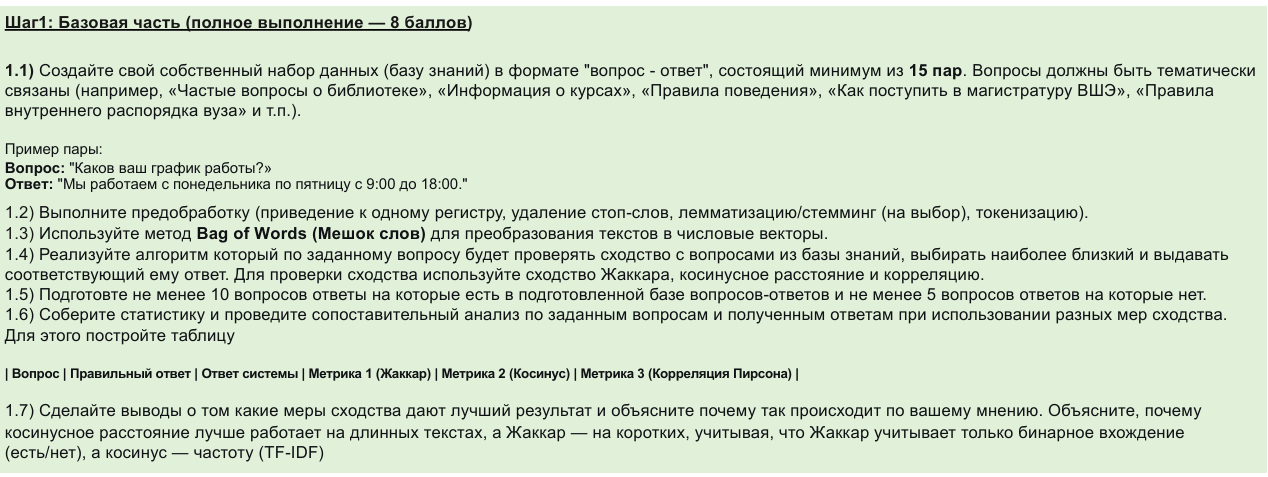

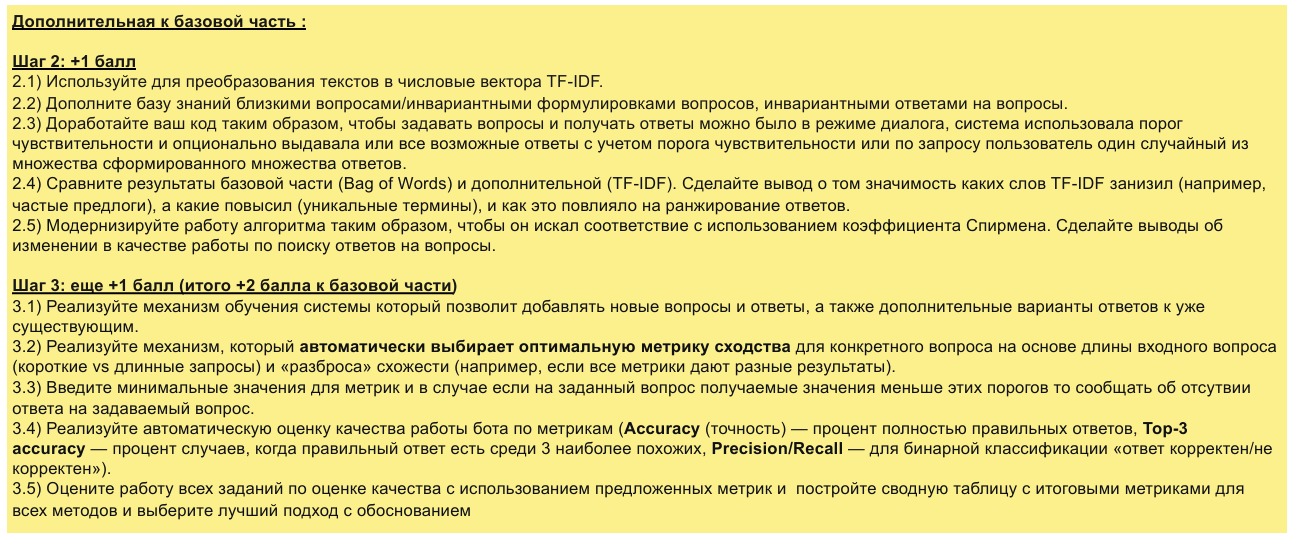